# MonReader — 02 Scratch CNN Selection and W&B Integration

> **Status:** historical pre-V2 model-selection notebook.  
> The current V2 protocol does **not** use this Bayesian/validation-based procedure.

## Purpose

This notebook records the completed scratch-CNN tuning experiment and presents a **portable W&B integration pattern**. The successful historical results remain visible from committed snapshots even when W&B is disabled.

### Portability rules

- No API key is committed.
- No W&B entity or username is hard-coded.
- No machine-specific path is used.
- Creating a new sweep is **opt-in**.
- A reviewer can inspect all successful historical results without a W&B account.

In [ ]:
from pathlib import Path
import sys

# Portable repository discovery: no machine-specific paths.
HERE = Path.cwd().resolve()
REPO_ROOT = next(
    (
        p for p in [HERE, *HERE.parents]
        if (p / "submission" / "results").is_dir()
    ),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Run this notebook from inside a clone of the MonReader repository."
    )

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from submission.src.repro import load_snapshot, figures_dir, data_root

print(f"Repository root: {REPO_ROOT}")
print(f"Optional local data root: {data_root() or 'not configured (report mode is still available)'}")


## Optional W&B setup

Environment variables:

```bash
MONREADER_ENABLE_WANDB=1
MONREADER_WANDB_PROJECT=my-monreader-project
MONREADER_WANDB_ENTITY=my-team              # optional
WANDB_API_KEY=...                           # or use `wandb login`
WANDB_MODE=online
MONREADER_CREATE_NEW_SWEEP=0                # keep 0 unless intentionally rerunning
```

The sweep definition below reproduces the historical search space but does **not** create a sweep unless `MONREADER_CREATE_NEW_SWEEP=1`.

In [ ]:
# Portable W&B integration. Nothing is created unless explicitly enabled.
import os
from submission.src.repro import WandbSettings, create_sweep

wandb_settings = WandbSettings.from_env()
print(wandb_settings)

HISTORICAL_SWEEP_CONFIG = {
    "method": "bayes",
    "metric": {"name": "val_f1", "goal": "maximize"},
    "parameters": {
        "optimizer": {"values": ["adam", "adamw", "sgd", "rmsprop"]},
        "learning_rate": {
            "distribution": "log_uniform_values",
            "min": 1e-5,
            "max": 1e-2,
        },
        "batch_size": {"distribution": "int_uniform", "min": 8, "max": 256},
        "weight_decay_mode": {"values": ["zero", "positive"]},
        "positive_weight_decay": {
            "distribution": "log_uniform_values",
            "min": 1e-6,
            "max": 1e-2,
        },
        "dropout": {"distribution": "uniform", "min": 0.0, "max": 0.5},
        "depth": {"distribution": "int_uniform", "min": 1, "max": 7},
        "starting_filters": {"distribution": "int_uniform", "min": 8, "max": 64},
    },
}

# Optional creation is deliberately separated from notebook display logic.
RUN_NEW_SWEEP = os.getenv("MONREADER_CREATE_NEW_SWEEP", "0") == "1"
new_sweep_id = (
    create_sweep(wandb_settings, HISTORICAL_SWEEP_CONFIG)
    if RUN_NEW_SWEEP
    else None
)
print("New sweep created:", new_sweep_id or "NO (report mode / opt-in disabled)")


## Historical sweep completion audit

| regime   |   all_runs |   finished_runs |   excluded_oom |   excluded_zero_f1 |   excluded_invalid_f1 |   QUALIFYING_RUNS |   TARGET | TARGET_REACHED   |
|:---------|-----------:|----------------:|---------------:|-------------------:|----------------------:|------------------:|---------:|:-----------------|
| O        |         38 |              36 |              2 |                  2 |                     2 |                30 |       30 | True             |
| S        |         37 |              37 |              5 |                  2 |                     0 |                30 |       30 | True             |
| T        |         31 |              31 |              1 |                  0 |                     0 |                30 |       30 | True             |
| ST       |         35 |              35 |              3 |                  2 |                     0 |                30 |       30 | True             |

The controller reached the required **30 qualifying finished runs per regime** after excluding invalid/OOM/zero-F1 attempts. The table is included as provenance only; the corrected final winner identities are shown next.

## Corrected frozen scratch-CNN winners

| regime   | run_id   | run_name          | winner_changed   |   best_epoch |   accuracy |   precision |   recall |     f1 |   roc_auc |   pr_auc |   loss |
|:---------|:---------|:------------------|:-----------------|-------------:|-----------:|------------:|---------:|-------:|----------:|---------:|-------:|
| O        | blalkdao | lilac-sweep-3     | False            |           11 |     1      |      1      |   1      | 1      |    1      |   1      | 0.0001 |
| S        | flrngfjg | winter-sweep-33   | False            |            2 |     1      |      1      |   1      | 1      |    1      |   1      | 0.0185 |
| T        | o9du79bv | major-sweep-15    | True             |            9 |     0.99   |      0.98   |   1      | 0.9899 |    0.9994 |   0.9993 | 0.0504 |
| ST       | za1irov4 | northern-sweep-28 | True             |            5 |     0.9747 |      0.9706 |   0.9788 | 0.9747 |    0.9983 |   0.9983 | 0.0573 |

The final reporting pass corrected winner identity for T and ST rather than silently retaining stale summary-metric rankings. These are the frozen historical scratch checkpoints used for downstream comparison.

## Validation and held-out metrics

| regime   | split         |   n_samples |   accuracy |   balanced_accuracy |   notflip_f1 |   flip_f1 |   macro_f1 |   roc_auc_flip |   pr_auc_flip |    mcc |
|:---------|:--------------|------------:|-----------:|--------------------:|-------------:|----------:|-----------:|---------------:|--------------:|-------:|
| O        | Validation    |         240 |     0.9917 |              0.9919 |       0.9918 |    0.9915 |     0.9917 |         0.9999 |        0.9999 | 0.9835 |
| O        | Held-out Test |         597 |     0.9899 |              0.9899 |       0.9902 |    0.9897 |     0.9899 |         0.9994 |        0.9994 | 0.9799 |
| S        | Validation    |         232 |     0.5474 |              0.5312 |       0.6957 |    0.1176 |     0.4066 |         0.9621 |        0.9606 | 0.1826 |
| S        | Held-out Test |         610 |     0.5951 |              0.5392 |       0.7347 |    0.1453 |     0.44   |         0.9519 |        0.9216 | 0.2133 |
| T        | Validation    |         301 |     0.9369 |              0.9382 |       0.9347 |    0.9389 |     0.9368 |         0.9948 |        0.996  | 0.8796 |
| T        | Held-out Test |         301 |     0.8306 |              0.8315 |       0.8271 |    0.8339 |     0.8305 |         0.89   |        0.917  | 0.6641 |
| ST       | Validation    |         475 |     0.8589 |              0.8581 |       0.8771 |    0.8346 |     0.8558 |         0.9598 |        0.9666 | 0.7479 |
| ST       | Held-out Test |         121 |     0.7934 |              0.7912 |       0.8148 |    0.7664 |     0.7906 |         0.8341 |        0.8005 | 0.5813 |

## Historical generalization summary

| regime   |   validation_macro_f1 |   test_macro_f1 |   validation_to_test_change |   test_drop_relative_to_O |
|:---------|----------------------:|----------------:|----------------------------:|--------------------------:|
| O        |                0.9917 |          0.9899 |                     -0.0017 |                    0      |
| S        |                0.4066 |          0.44   |                      0.0334 |                    0.5499 |
| T        |                0.9368 |          0.8305 |                     -0.1063 |                    0.1594 |
| ST       |                0.8558 |          0.7906 |                     -0.0652 |                    0.1994 |

## Baseline versus tuned scratch CNN

| model          | split         |   n_samples |   accuracy |   balanced_accuracy |   notflip_f1 |   flip_f1 |   macro_f1 |   roc_auc_flip |   pr_auc_flip |    mcc |
|:---------------|:--------------|------------:|-----------:|--------------------:|-------------:|----------:|-----------:|---------------:|--------------:|-------:|
| Fixed Baseline | Validation    |         240 |     0.6375 |              0.6282 |       0.7387 |    0.4082 |     0.5735 |         0.8481 |        0.8793 | 0.3875 |
| Fixed Baseline | Held-out Test |         597 |     0.6265 |              0.6156 |       0.7329 |    0.3788 |     0.5559 |         0.8204 |        0.8495 | 0.3615 |
| Tuned Scratch  | Validation    |         240 |     0.9917 |              0.9919 |       0.9918 |    0.9915 |     0.9917 |         0.9999 |        0.9999 | 0.9835 |
| Tuned Scratch  | Held-out Test |         597 |     0.9899 |              0.9899 |       0.9902 |    0.9897 |     0.9899 |         0.9994 |        0.9994 | 0.9799 |

| split         |   baseline_macro_f1 |   tuned_macro_f1 |   absolute_macro_f1_gain |   macro_f1_error_reduction_pct |   accuracy_gain |
|:--------------|--------------------:|-----------------:|-------------------------:|-------------------------------:|----------------:|
| Validation    |              0.5735 |           0.9917 |                   0.4182 |                        98.0458 |          0.3542 |
| Held-out Test |              0.5559 |           0.9899 |                   0.4341 |                        97.7352 |          0.3635 |

## Confusion matrices for the corrected frozen scratch winners

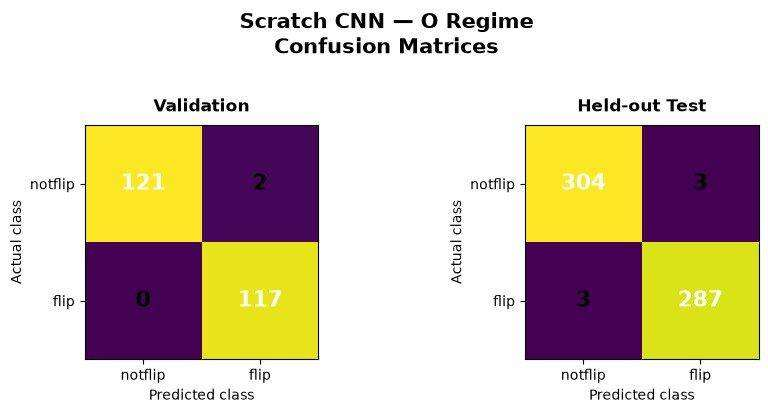

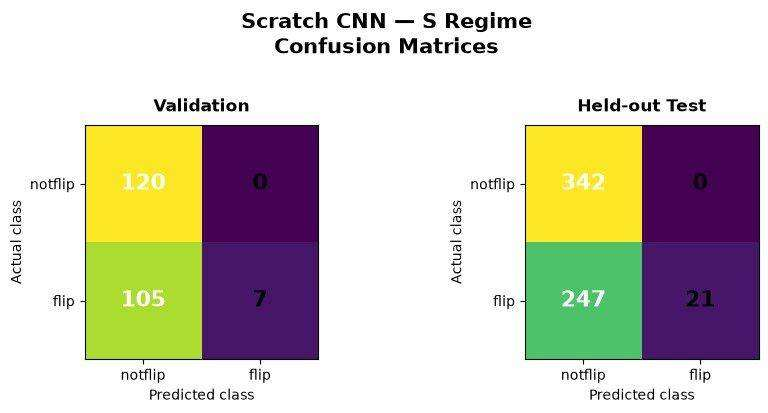

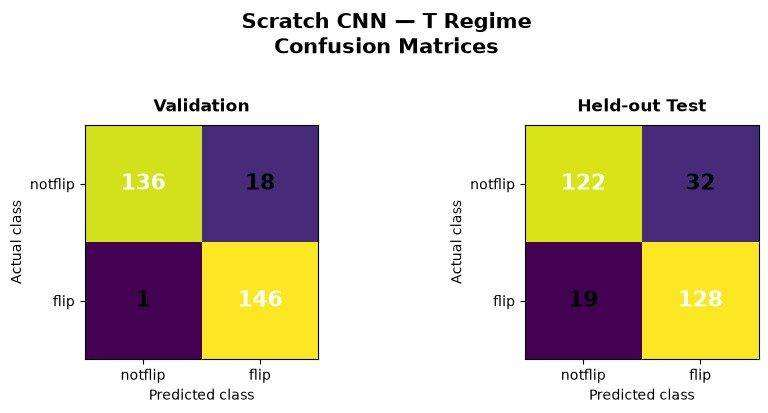

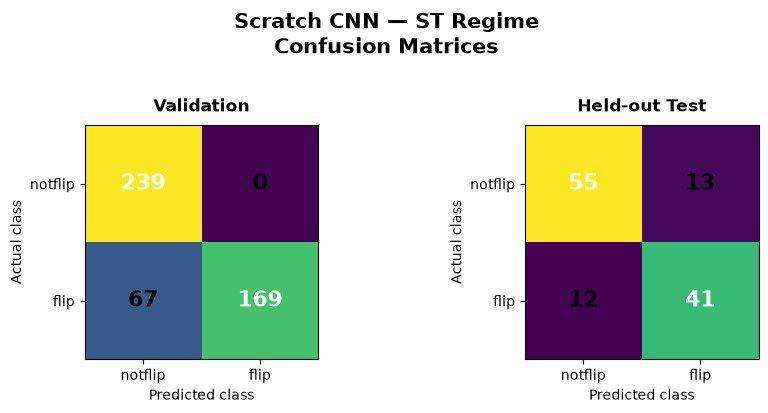


## Generalization figures

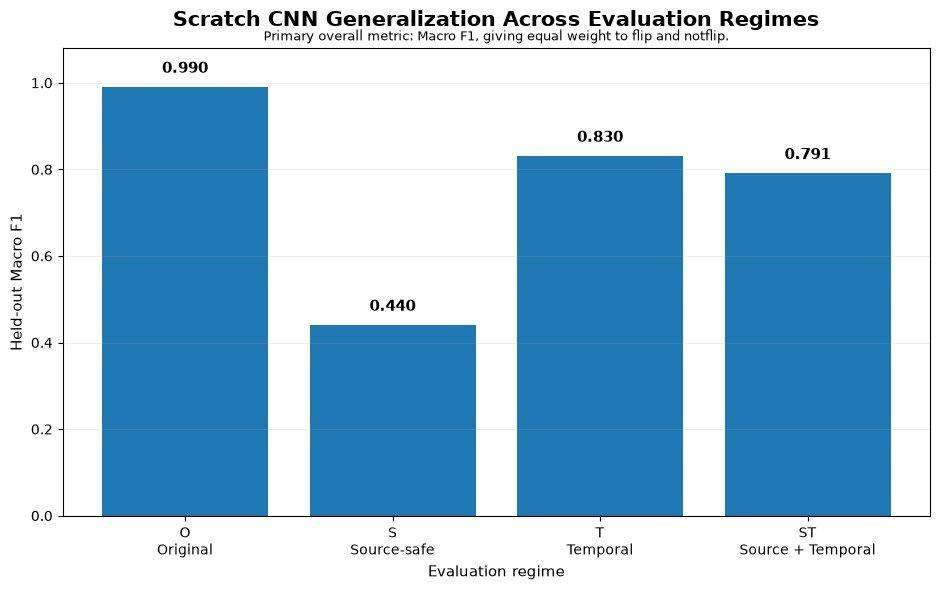

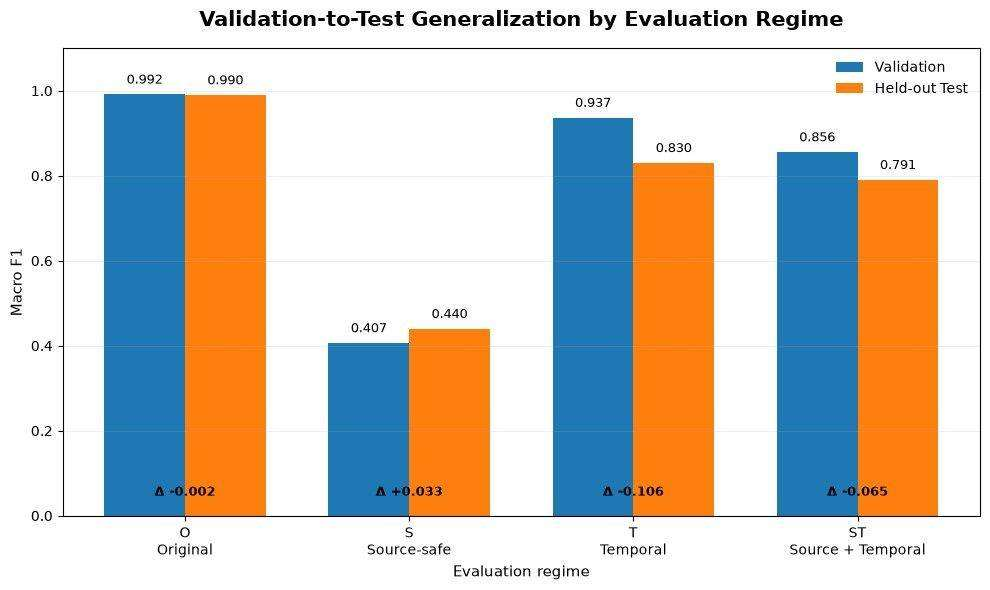

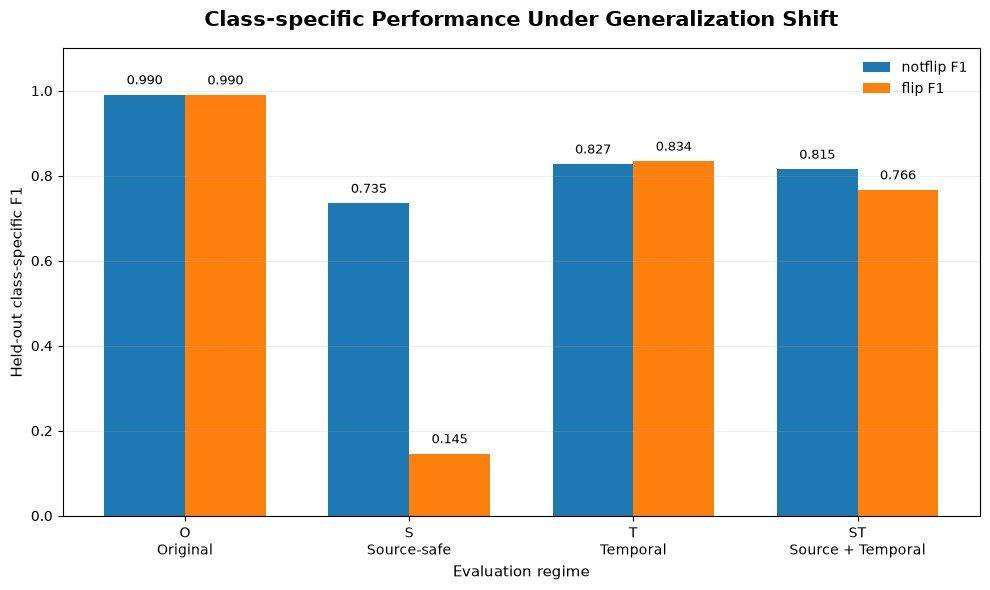

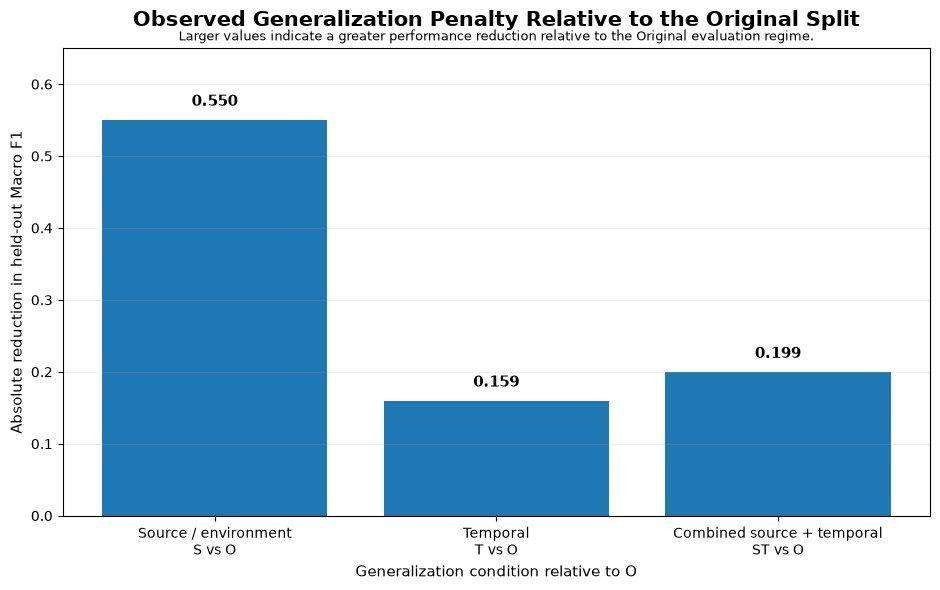

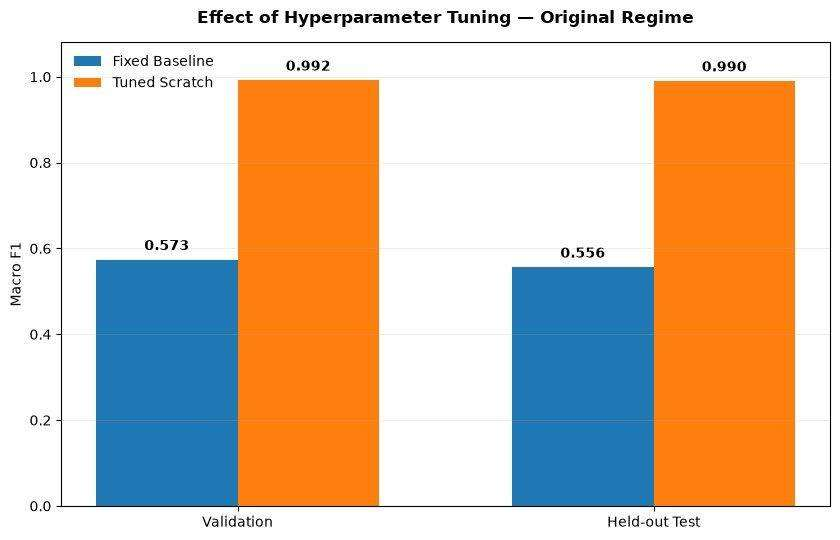

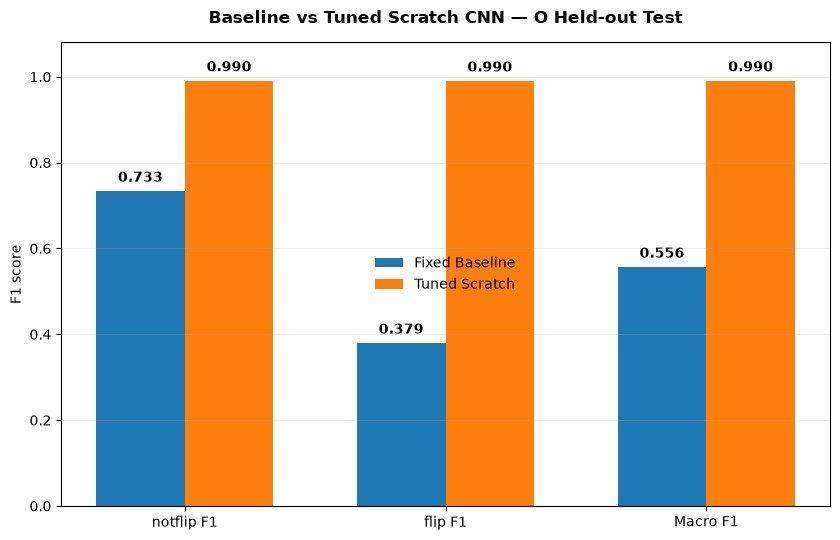


## Interpretation

The tuned scratch CNN nearly saturated the O regime (held-out Macro F1 ≈ **0.990**) but deteriorated sharply under source-safe evaluation (**0.440**). T and ST were materially harder than O but less catastrophic for the tuned scratch model (**0.830** and **0.791**).

This was the first strong indication that the supplied O split was not a sufficient robustness estimate. Notebook 3 therefore compares the scratch model with a pretrained ResNet18 and examines the historical RGB/grayscale branch.

> **Method-status note:** the Bayesian search and validation-based winner selection in this notebook are historical only. Current V2 uses a prospectively frozen train/test protocol instead.